# Projeto - técnicas de programação I
Elaborado por ***Alessandra Mara Nébias*** |
[Github do Projeto](https://github.com/anebias/ProjetoAdaTech_TecnicasProgramacao.git)

***O objetivo desse projeto é analisar as contratações do produto de crédito FUNGETUR entre os anos de 2023 a 2026 (parcial), observando as finalidades de financiamento, regiões, agentes financeiros e concentração de tomadores de crédito.***

🏦 Conjunto de Dados Operações de Financiamento FUNGETUR

- https://dados.turismo.gov.br/dataset/operacoes-de-financiamento-fungetur-2023
- https://dados.turismo.gov.br/dataset/operacoes-de-financiamento-fungetur-2024
- https://dados.turismo.gov.br/dataset/operacoes-de-financiamento-fungetur-2025
- https://dados.turismo.gov.br/dataset/operacoes-de-financiamento-fungetur-2026

## SETUP
Configurações gerais do pipeline

### Bibliotecas utilizadas no projeto

In [1]:
# Biblioteca para sistema operacional
import os

# Conectar Google Drive para leitura dos arquivos CSV
from google.colab import drive

# Bibliotecas para análise de dados e gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Caminhos, variáveis e lista dos arquivos

In [2]:
# Montar o Google Drive
drive.mount('/content/drive')

# Pasta que armazena os arquivos CSV baixados com dados FUNGETUR
pasta_caixaverso = '/content/drive/MyDrive/CAIXAVERSO '

lista_anos = ['23', '24', '25', '26', '27']

lista_arquivos = []
for ano in lista_anos:
  try:
    nome_arquivo = f'operacoes-de-financiamento-fungetur-{ano}.csv'
    caminho_arquivo = os.path.join(pasta_caixaverso, nome_arquivo)
    if not os.path.exists(caminho_arquivo):
      print(f'arquivo "operacoes-de-financiamento-fungetur-{ano}" não encontrado.')
    else:
      lista_arquivos.append(f'operacoes-de-financiamento-fungetur-{ano}.csv')
  except ValueError as e:
    print(f'arquivo "operacoes-de-financiamento-fungetur-{ano}" não encontrado.')

print('*'*10,'Lista dos arquivos no drive','*'*10)
for arquivo in lista_arquivos:
  print(f'{arquivo}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
arquivo "operacoes-de-financiamento-fungetur-27" não encontrado.
********** Lista dos arquivos no drive **********
operacoes-de-financiamento-fungetur-23.csv
operacoes-de-financiamento-fungetur-24.csv
operacoes-de-financiamento-fungetur-25.csv
operacoes-de-financiamento-fungetur-26.csv


### Carga e reconhecimento dos dados...

In [3]:
def carga_dados(pasta_caixaverso, arquivo):
  caminho_completo = os.path.join(pasta_caixaverso, arquivo)
  df_lido = pd.read_csv(caminho_completo, sep=';', encoding='latin-1', decimal=',')
  ano = arquivo.split('-')[-1].split('.')[0]
  return df_lido, ano

In [4]:
dfs = {}

for arquivo in lista_arquivos:
  df_lido, ano = carga_dados(pasta_caixaverso, arquivo)
  print(ano)
  dfs[f'df_{ano}'] = pd.DataFrame(df_lido)
  print(dfs[f'df_{ano}'].shape)

23
(3393, 17)
24
(2064, 17)
25
(1254, 17)
26
(2064, 17)


In [5]:
for nome, df in dfs.items():
  print(f"{nome}: {df.shape}")

df_23: (3393, 17)
df_24: (2064, 17)
df_25: (1254, 17)
df_26: (2064, 17)


In [6]:
# ordenas os nomes dos dataframes para comparação,
nomes_dfs = sorted(dfs.keys())
print(f'Nome dos dataframes ordenados: \n{nomes_dfs}')
df_referencia = nomes_dfs[0]

# Definindo o primeiro conjuntos de colunas como referência
colunas_referencia = set(dfs[df_referencia].columns)
print(f'Nome das colunas de referência: \n{colunas_referencia}')

Nome dos dataframes ordenados: 
['df_23', 'df_24', 'df_25', 'df_26']
Nome das colunas de referência: 
{'Fin. Taxa de Atualização Monetária', 'Descrição CNAE', 'Spread Bancário', 'Data Fim do Contrato', 'CNAE', 'UF', ' Valor Contratado ', 'Finalidade do Financiamento', 'Município', 'Porte da Empresa', 'CPF/CNPJ do Contratante', 'Carência (Meses)', 'Agente Financeiro', 'Prazo (Meses)', 'Atividade Turística', 'Nome / Razão Social', 'Data Início do Contrato'}


In [7]:
if nomes_dfs:
    todas_colunas_iguais = True
    for nome in nomes_dfs[1:]:
        colunas_atual = set(dfs[nome].columns)
        print(f"Comparando {df_referencia} com {nome}:")

        if colunas_referencia == colunas_atual:
            print(f"  - Ambos possuem exatamente as mesmas {len(colunas_referencia)} colunas.")
        else:
            todas_colunas_iguais = False
            a_mais = colunas_atual - colunas_referencia
            a_menos = colunas_referencia - colunas_atual

            if a_mais:
                print(f"  - Colunas exclusivas de {nome}: {a_mais}")
            if a_menos:
                print(f"  - Colunas faltantes em {nome} (existem em {df_referencia}): {a_menos}")
        print()

    if todas_colunas_iguais:
        print("Conclusão: Todos os DataFrames possuem o mesmo conjunto de colunas!")
    else:
        print("Conclusão: Há divergências nos nomes de colunas entre os anos analisados.")
else:
    print("Nenhum DataFrame encontrado no dicionário 'dfs'.")

Comparando df_23 com df_24:
  - Ambos possuem exatamente as mesmas 17 colunas.

Comparando df_23 com df_25:
  - Ambos possuem exatamente as mesmas 17 colunas.

Comparando df_23 com df_26:
  - Ambos possuem exatamente as mesmas 17 colunas.

Conclusão: Todos os DataFrames possuem o mesmo conjunto de colunas!


In [8]:
# Analisar os tipos de cada coluna em cada dataframe e comparar se são os mesmos

colunas_com_tipos_diferentes = []
print('*'*10, 'Análise dos tipos das colunas' ,'*'*10)
for coluna in colunas_referencia:
  print(f'- {coluna}:')
  tipo_coluna_referencia = dfs[df_referencia][coluna].dtype
  todos_tipos_iguais = True

  for nome in nomes_dfs:
    tipo_coluna = dfs[nome][coluna].dtype

    print(f'{nome}: {tipo_coluna}')

    if tipo_coluna != tipo_coluna_referencia and coluna not in colunas_com_tipos_diferentes:
      todos_tipos_iguais = False
      colunas_com_tipos_diferentes.append(coluna)

  print()
print(f'Colunas com tipos diferentes: {colunas_com_tipos_diferentes}')
print()

********** Análise dos tipos das colunas **********
- Fin. Taxa de Atualização Monetária:
df_23: object
df_24: object
df_25: object
df_26: object

- Descrição CNAE:
df_23: object
df_24: object
df_25: object
df_26: object

- Spread Bancário:
df_23: float64
df_24: float64
df_25: float64
df_26: float64

- Data Fim do Contrato:
df_23: object
df_24: object
df_25: object
df_26: object

- CNAE:
df_23: object
df_24: object
df_25: object
df_26: object

- UF:
df_23: object
df_24: object
df_25: object
df_26: object

-  Valor Contratado :
df_23: object
df_24: object
df_25: object
df_26: object

- Finalidade do Financiamento:
df_23: object
df_24: object
df_25: object
df_26: object

- Município:
df_23: object
df_24: object
df_25: object
df_26: object

- Porte da Empresa:
df_23: object
df_24: object
df_25: object
df_26: object

- CPF/CNPJ do Contratante:
df_23: float64
df_24: int64
df_25: float64
df_26: float64

- Carência (Meses):
df_23: object
df_24: object
df_25: float64
df_26: float64

- Agente F

In [9]:
# Gerar relatório de cada ano com impressão do head(n),
# de modo que cada registro fique em uma linha para análise visual dos dados

itens_head = 3
print('*'*10, f'{itens_head} REGISTROS POR COLUNA' ,'*'*10)
for coluna in colunas_referencia:
  print(f'- {coluna}:')

  for nome in nomes_dfs:
    for i in range(itens_head):
      print(f'{nome}: {dfs[nome][coluna].values[i]}')
    print()
  print()

print()

********** 3 REGISTROS POR COLUNA **********
- Fin. Taxa de Atualização Monetária:
df_23: INPC
df_23: INPC
df_23: INPC

df_24: INPC
df_24: INPC
df_24: INPC

df_25: INPC
df_25: INPC
df_25: INPC

df_26: INPC
df_26: INPC
df_26: INPC


- Descrição CNAE:
df_23: RESTAURANTES E SIMILARES
df_23: FABRICAÇÃO DE PRODUTOS DE PADARIA E CONFEITARIA COM PREDOMINÂNCIA DE PRODUÇÃO PRÓPRIA
df_23: FABRICAÇÃO DE PRODUTOS DE PADARIA E CONFEITARIA COM PREDOMINÂNCIA DE PRODUÇÃO PRÓPRIA

df_24: FABRICAÇÃO DE PRODUTOS DE PADARIA E CONFEITARIA COM PREDOMINÂNCIA DE PRODUÇÃO PRÓPRIA
df_24: COMERCIO VAREJISTA DE SUVENIRES, BIJUTERIAS E ARTESANATOS
df_24: COMÉRCIO VAREJISTA DE ARTIGOS DO VESTUÁRIO E ACESSÓRIOS

df_25: NONE
df_25: ATIVIDADES DE APOIO A PESCA EM ÁGUA DOCE
df_25: FABRICAÇÃO DE PRODUTOS DERIVADOS DO CACAU E DE CHOCOLATES

df_26: NONE
df_26: ATIVIDADES DE APOIO A PESCA EM ÁGUA SALGADA
df_26: IMPRESSÃO DE MATERIAL PARA USO PUBLICITÁRIO


- Spread Bancário:
df_23: 5.0
df_23: 4.88
df_23: 4.88

df_24: 4.88


In [10]:
# Gerar relatório INFO para cada ano

for nome in nomes_dfs:
  print(f'{'*'*10} {nome} {'*'*10}')
  dfs[nome].info()
  print()
print()


********** df_23 **********
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3393 entries, 0 to 3392
Data columns (total 17 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Agente Financeiro                   1921 non-null   object 
 1   CPF/CNPJ do Contratante             1921 non-null   float64
 2   Nome / Razão Social                 1921 non-null   object 
 3   UF                                  1921 non-null   object 
 4   Município                           1921 non-null   object 
 5    Valor Contratado                   1921 non-null   object 
 6   Data Início do Contrato             1921 non-null   object 
 7   Data Fim do Contrato                1921 non-null   object 
 8   Prazo (Meses)                       1921 non-null   object 
 9   Carência (Meses)                    1595 non-null   object 
 10  Spread Bancário                     1921 non-null   float64
 11  Fin. Taxa de At

In [11]:
# Gerar relatório DESCRIBE para cada ano

for nome in nomes_dfs:
  print(f'{'*'*10} {nome} {'*'*10}')
  print(dfs[nome].describe())
  print()
print()

********** df_23 **********
       CPF/CNPJ do Contratante  Spread Bancário
count             1.921000e+03      1921.000000
mean              2.970972e+13         4.961130
std               1.963923e+13         0.221607
min               8.253500e+10         3.000000
25%               1.316075e+13         5.000000
50%               2.898774e+13         5.000000
75%               4.207871e+13         5.000000
max               9.754686e+13         5.450000

********** df_24 **********
       CPF/CNPJ do Contratante  Spread Bancário
count             2.064000e+03      2064.000000
mean              2.968651e+13         9.242083
std               1.941443e+13        46.043832
min               5.873300e+10         0.050000
25%               1.330060e+13         5.000000
50%               2.861214e+13         5.000000
75%               4.300450e+13         5.000000
max               9.859772e+13       500.000000

********** df_25 **********
       CPF/CNPJ do Contratante  Prazo (Meses)  Car

### Contatações do reconhecimento dos dados:

No ano 2023:
- o arquivo apresentou 3393 registros, mas apenas 1921 registros não nulos em todas as variáveis. Portanto, antes de incluir a variável ANO ao dataframe, é aconselhável analisar se a linha possui valores não nulos. Se a linha possui valores nulos em todas as variáveis, não inserir essa linha ao dataframe de análise.

No ano 2024:
- O arquivo apresentou 2064 registros com 2064 valores não nulos em quase todas as variáveis. A variável "Prazo (Meses)" apresentou 2064 registros não nulos e a variável "Carência (Meses)" apresentou 1740 registros não nulos.

No ano 2025:
- O arquivo apresentou 1254 registros com 1254 valores não nulos em quase todas as variáveis. A variável "Carência (Meses)" apresentou 960 registros não nulos.

No ano 2026:
- O arquivo apresentou 2064 registros com 134 valores não nulos em quase todas as variáveis. A variável "Carência (Meses)" apresentou 86 registros não nulos.

Análise das colunas:

  - 17 colunas em todos os anos;
  
  - "CPF/CNPJ do Contratante": Armazenado como  float em 2023, 2025 e 2026 e como inteiro em 2024. Normalizar para object.

  - "Data Início do Contrato": Armazenado como object no formato dd/mm/aaaa. Normalizar para data;
  
  - "Data Fim do Contrato": Armazenado como object no formato dd/mm/aaaa. Normalizar para data;

  - "Prazo (Meses)": Armazenado com object em 2023 e 2024, inteiro em 2025 e float em 2026. Normalizar para inteiro;

  - "Carência (Meses)": Armazenado com object em 2023 e 2024 e float em 2025 e 2026. Normalizar para inteiro;
    
  - " Valor Contratado": está com espaço no início do nome da variável, armazenado como object em todos os anos, valores com símbolo (R$). Remover símbolo e normalizar para float;

  - Demais colunas com tipos compatíveis com os dados armazenados.

In [12]:
def carga_dados_validos(pasta_caixaverso, arquivo):
  caminho_completo = os.path.join(pasta_caixaverso, arquivo)
  # Adicionado o parâmetro dayfirst=True para tratar o formato de data brasileiro (dd/mm/aaaa)
  df_lido = pd.read_csv(caminho_completo, sep=';', encoding='latin-1', decimal=',', parse_dates=['Data Início do Contrato', 'Data Fim do Contrato'], dayfirst=True)
  ano = arquivo.split('-')[-1].split('.')[0]

  # Remove registros onde todas as colunas são nulas
  df_validado = df_lido.dropna(how='all')

  return df_validado, ano

In [13]:
## Criação do dataframe para análise dos dados

df_lista = []

for arquivo in lista_arquivos:
  df_validado, ano = carga_dados_validos(pasta_caixaverso, arquivo)
  print(f"Ano: {ano} | Registros válidos: {df_validado.shape[0]}")

  # Adiciona a coluna com o ano correspondente
  df_validado = df_validado.copy()
  df_validado['ANO'] = ano

  df_lista.append(df_validado)

# Concatena todos os dataframes válidos em um único dataframe de análise
df = pd.concat(df_lista, ignore_index=True)

print(f"\nShape final do DataFrame unificado: {df.shape}")

Ano: 23 | Registros válidos: 1921
Ano: 24 | Registros válidos: 2064
Ano: 25 | Registros válidos: 1254
Ano: 26 | Registros válidos: 134

Shape final do DataFrame unificado: (5373, 18)


### Funções de Tratamento por Responsabilidade
Definição de funções modulares para normalização de dados específicos, com docstrings.

In [14]:
def tratar_cnpj_cpf(col):
    """Normaliza a coluna de CPF/CNPJ para tipo object (string)"""
    # Converte para string e remove o ".0" se houver conversão indesejada de float
    col_limpa = col.astype(str).str.replace(r'\.0$', '', regex=True)
    # Substitui representações de valores nulos por nulo real do pandas
    col_limpa = col_limpa.replace(['nan', 'None', '<NA>'], np.nan)
    return col_limpa

def tratar_inteiro(col):
    """Normaliza colunas numéricas para o tipo Int64 (aceita nulos)"""
    # Converte os valores para numérico primeiro, forçando erros a virarem NaN
    num_col = pd.to_numeric(col, errors='coerce')
    # Converte para o tipo Int64 do pandas
    return num_col.astype('Int64')

def tratar_valor_contratado(col):
    """Limpa caracteres monetários e converte valores para float"""
    # Remove R$, espaços em branco e pontos de milhar
    col_limpa = col.astype(str).str.replace('R$', '', regex=False)
    col_limpa = col_limpa.str.replace('.', '', regex=False)
    col_limpa = col_limpa.str.replace(',', '.', regex=False)
    col_limpa = col_limpa.str.strip()

    # Converte para float
    num_col = pd.to_numeric(col_limpa, errors='coerce')
    return num_col

### Função Principal de Normalização
Função integradora que mapeia, corrige nomes de colunas e chama as funções especializadas.

In [15]:
def normalizar_dataframe(df_entrada):
    """Aplica todos os tratamentos específicos no DataFrame integrado"""
    df_novo = df_entrada.copy()

    # Ajusta o nome da coluna com espaços extras (' Valor Contratado ')
    # Também limpa nomes de todas as outras colunas para evitar futuros problemas
    df_novo.columns = df_novo.columns.str.strip()

    # 1) Normalizar CPF/CNPJ do Contratante para object
    if 'CPF/CNPJ do Contratante' in df_novo.columns:
        df_novo['CPF/CNPJ do Contratante'] = tratar_cnpj_cpf(df_novo['CPF/CNPJ do Contratante'])

    # 2) Normalizar Prazo (Meses) para inteiro
    if 'Prazo (Meses)' in df_novo.columns:
        df_novo['Prazo (Meses)'] = tratar_inteiro(df_novo['Prazo (Meses)'])

    # 3) Normalizar Carência (Meses) para inteiro
    if 'Carência (Meses)' in df_novo.columns:
        df_novo['Carência (Meses)'] = tratar_inteiro(df_novo['Carência (Meses)'])

    # 4) Normalizar Valor Contratado para float
    if 'Valor Contratado' in df_novo.columns:
        df_novo['Valor Contratado'] = tratar_valor_contratado(df_novo['Valor Contratado'])

    return df_novo

In [16]:
# Aplicação da normalização no DataFrame unificado
df_normalizado = normalizar_dataframe(df)

# Exibição do resultado para validação rápida
print('Shape do dataframe após normalização:')
display(df_normalizado.shape)

print('\nTipos de dados após a normalização:\n')
display(df_normalizado.info())

print('\nVisualização das primeiras linhas:')
display(df_normalizado[['CPF/CNPJ do Contratante', 'Prazo (Meses)', 'Carência (Meses)', 'Valor Contratado']].head())

Shape do dataframe após normalização:


(5373, 18)


Tipos de dados após a normalização:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5373 entries, 0 to 5372
Data columns (total 18 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Agente Financeiro                   5373 non-null   object        
 1   CPF/CNPJ do Contratante             5373 non-null   object        
 2   Nome / Razão Social                 5373 non-null   object        
 3   UF                                  5373 non-null   object        
 4   Município                           5373 non-null   object        
 5   Valor Contratado                    5373 non-null   float64       
 6   Data Início do Contrato             5373 non-null   datetime64[ns]
 7   Data Fim do Contrato                5373 non-null   datetime64[ns]
 8   Prazo (Meses)                       5367 non-null   Int64         
 9   Carência (Meses)                    4351 non-null   Int64 

None


Visualização das primeiras linhas:


,CPF/CNPJ do Contratante,Prazo (Meses),Carência (Meses),Valor Contratado
0,43277886000128,72,1,85000.0
1,24897022000164,30,4,200000.0
2,18589072000181,30,4,100000.0
3,81167660000163,30,1,348000.0
4,31616617000160,30,1,152000.0


### ❗ A análise de dados seguirá usando o dataframe normalizado, uma vez que ele foi obtivoapós a avaliação dos valores carregados e tratamento para sua normalização (df_normalizado)

In [17]:
# Análise das colunas incompletas: 'Prazo (Meses)' e 'Carência (Meses)'

df_normalizado[['Prazo (Meses)', 'Carência (Meses)']].describe()

,Prazo (Meses),Carência (Meses)
count,5367.0,4351.0
mean,67.53829,9.115606
std,114.652607,27.02943
min,1.0,1.0
25%,48.0,3.0
50%,60.0,6.0
75%,69.0,12.0
max,3834.0,759.0


In [18]:
# Contando os valores nulos em todas as colunas do DataFrame normalizado
df_normalizado[['Prazo (Meses)','Carência (Meses)']].isna().sum()

,0
Prazo (Meses),6
Carência (Meses),1022


In [19]:
# Analisando os prazos em anos:
print('Prazo (Meses) em anos:')
display(df_normalizado['Prazo (Meses)'].max() / 12)

print('Carência (Meses) em anos:')
display(df_normalizado['Carência (Meses)'].max() / 12)


Prazo (Meses) em anos:


np.float64(319.5)

Carência (Meses) em anos:


np.float64(63.25)

In [20]:
# Visualizando os valores únicos da finalidade do financiamento
df_normalizado['Finalidade do Financiamento'].unique()

array(['CAPITAL GIRO', 'OBRA', 'OBRA CAPITAL GIRO', 'BEM', 'BEM OBRA',
       'BEM CAPITAL GIRO'], dtype=object)

Nessa análise observamos que os prazos máximos presentes na base sugerem inconsistência, pois prazo de contratação de **319 anos** e carência de **63 anos** extrapolam a razoabilidade.

Desta forma, foram analisadas as finalidades de financiamento presentes na base e pesquisa para identificar os prazos previstos para o produto de crédito para cada finalidade.

Conforme consulta realizada, os prazos máximos para as finalidades presentes na base analisada são:

*   Capital de giro: 120 meses, com 48 de carência
*   Obra: 240 meses, com 60 de carência
*   Obra capital de giro: 240 meses, com 60 de carência
*   Bem: 120 meses, com 48 de carência
*   Bem obra: 240 meses, com 60 de carência
*   Bem capital de giro: 120 meses, com 48 de carência



In [21]:
# Dicionário com valores máximos do produto de crédito FUNGETUR

prazos_maximos = {
    'CAPITAL GIRO': [120, 48],
    'OBRA': [240, 60],
    'OBRA CAPITAL GIRO': [240, 60],
    'BEM': [120, 48],
    'BEM OBRA': [240, 60],
    'BEM CAPITAL GIRO': [120, 48]
}

In [22]:
# Analisar e contar quantos registros superam o prazo e a carência máximos por finalidade
resultados = []

for finalidade, limites in prazos_maximos.items():
    prazo_limite, carencia_limite = limites

    # Filtrando as operações dessa finalidade
    df_filtrado = df_normalizado[df_normalizado['Finalidade do Financiamento'] == finalidade]

    # Contando quantos registros superam o prazo ou a carência
    excede_prazo = (df_filtrado['Prazo (Meses)'] > prazo_limite).sum()
    excede_carencia = (df_filtrado['Carência (Meses)'] > carencia_limite).sum()
    excede_ambos = ((df_filtrado['Prazo (Meses)'] > prazo_limite) & (df_filtrado['Carência (Meses)'] > carencia_limite)).sum()
    percentual_excede_prazo = (excede_prazo / len(df_filtrado)) * 100
    percentual_excede_carencia = (excede_carencia / len(df_filtrado)) * 100

    resultados.append({
        'Finalidade': finalidade,
        'Prazo Máx (M)': prazo_limite,
        'Carência Máx (M)': carencia_limite,
        'Qtd Excede Prazo': excede_prazo,
        'Qtd Excede Carência': excede_carencia,
        'Qtd Excede Ambos': excede_ambos,
        'Total Operações': len(df_filtrado),
        '% Excede Prazo': f'{percentual_excede_prazo:.6f}%',
        '% Excede Carência': f'{percentual_excede_carencia:.6f}%'
    })

# Exibindo o resultado como DataFrame para melhor visualização
pd.DataFrame(resultados)

,Finalidade,Prazo Máx (M),Carência Máx (M),Qtd Excede Prazo,Qtd Excede Carência,Qtd Excede Ambos,Total Operações,% Excede Prazo,% Excede Carência
0,CAPITAL GIRO,120,48,27,8,6,5035,0.536246%,0.158888%
1,OBRA,240,60,2,0,0,78,2.564103%,0.000000%
2,OBRA CAPITAL GIRO,240,60,0,0,0,10,0.000000%,0.000000%
3,BEM,120,48,2,1,1,150,1.333333%,0.666667%
4,BEM OBRA,240,60,0,2,0,62,0.000000%,3.225806%
5,BEM CAPITAL GIRO,120,48,3,2,2,38,7.894737%,5.263158%


In [23]:
# Variáveis auxiliares de nomenclatura
nome_coluna_prazo = 'Prazo (Meses)'
nome_coluna_carencia = 'Carência (Meses)'
nome_coluna_porte = 'Porte da Empresa'
nome_coluna_agente = 'Agente Financeiro'
nome_coluna_finalidade = 'Finalidade do Financiamento'

In [24]:
# Criamos cópias em float para permitir o preenchimento com médias decimais sem erro de tipo
coluna_prazo = df_normalizado[nome_coluna_prazo].astype(float)
coluna_carencia = df_normalizado[nome_coluna_carencia].astype(float)

# Preparação para as estratégias 5, 6 e 7 (Tratamento de Outliers)
df_est5 = df_normalizado.copy()
df_est6 = df_normalizado.copy()
df_est7 = df_normalizado.copy()

df_est5[nome_coluna_prazo] = df_est5[nome_coluna_prazo].astype(float)
df_est5[nome_coluna_carencia] = df_est5[nome_coluna_carencia].astype(float)
df_est6[nome_coluna_prazo] = df_est6[nome_coluna_prazo].astype(float)
df_est6[nome_coluna_carencia] = df_est6[nome_coluna_carencia].astype(float)
df_est7[nome_coluna_prazo] = df_est7[nome_coluna_prazo].astype(float)
df_est7[nome_coluna_carencia] = df_est7[nome_coluna_carencia].astype(float)

for finalidade, limites in prazos_maximos.items():
    prazo_limite, carencia_limite = limites

    # Filtro de finalidade
    mask_finalidade = df_normalizado[nome_coluna_finalidade] == finalidade

    # --- ESTRATÉGIA 5: Substituir pelo Máximo Previsto ---
    df_est5.loc[mask_finalidade & (df_est5[nome_coluna_prazo] > prazo_limite), nome_coluna_prazo] = float(prazo_limite)
    df_est5.loc[mask_finalidade & (df_est5[nome_coluna_carencia] > carencia_limite), nome_coluna_carencia] = float(carencia_limite)

    # Filtra os válidos para calcular médias e medianas específicas
    mask_validos = (df_normalizado[nome_coluna_finalidade] == finalidade) & (df_normalizado[nome_coluna_prazo] <= prazo_limite) & (df_normalizado[nome_coluna_carencia] <= carencia_limite)
    df_validos_sub = df_normalizado[mask_validos]

    media_prazo_valido = float(df_validos_sub[nome_coluna_prazo].mean())
    media_carencia_valido = float(df_validos_sub[nome_coluna_carencia].mean())
    mediana_prazo_valido = float(df_validos_sub[nome_coluna_prazo].median())
    mediana_carencia_valido = float(df_validos_sub[nome_coluna_carencia].median())

    mask_invalido_prazo = (df_normalizado[nome_coluna_finalidade] == finalidade) & (df_normalizado[nome_coluna_prazo] > prazo_limite)
    mask_invalido_carencia = (df_normalizado[nome_coluna_finalidade] == finalidade) & (df_normalizado[nome_coluna_carencia] > carencia_limite)

    # --- ESTRATÉGIA 6: Substituir pela Média dos Válidos ---
    df_est6.loc[mask_invalido_prazo, nome_coluna_prazo] = media_prazo_valido
    df_est6.loc[mask_invalido_carencia, nome_coluna_carencia] = media_carencia_valido

    # --- ESTRATÉGIA 7: Substituir pela Mediana dos Válidos ---
    df_est7.loc[mask_invalido_prazo, nome_coluna_prazo] = mediana_prazo_valido
    df_est7.loc[mask_invalido_carencia, nome_coluna_carencia] = mediana_carencia_valido

# --- IMPRESSÃO DOS COMPARATIVOS ---
print('*'*10, 'PRAZO', '*'*10)
print(f"original              : {len(df_normalizado):>3} linhas | média {coluna_prazo.mean():>8.2f} | desvio {coluna_prazo.std():>8.2f}")
print(f"5. máximo previsto    : {len(df_normalizado):>3} linhas | média {df_est5[nome_coluna_prazo].mean():>8.2f} | desvio {df_est5[nome_coluna_prazo].std():>8.2f}")
print(f"6. média dos válidos  : {len(df_normalizado):>3}  linhas | média {df_est6[nome_coluna_prazo].mean():>8.2f} | desvio {df_est6[nome_coluna_prazo].std():>8.2f}")
print(f"7. mediana dos válidos: {len(df_normalizado):>3}  linhas | média {df_est7[nome_coluna_prazo].mean():>8.2f} | desvio {df_est7[nome_coluna_prazo].std():>8.2f}")

print('\n' + '*'*10, 'CARÊNCIA', '*'*10)
print(f"original              : {len(df_normalizado):>3} linhas | média {coluna_carencia.mean():>8.2f} | desvio {coluna_carencia.std():>8.2f}")
print(f"5. máximo previsto    : {len(df_normalizado):>3} linhas | média {df_est5[nome_coluna_carencia].mean():>8.2f} | desvio {df_est5[nome_coluna_carencia].std():>8.2f}")
print(f"6. média dos válidos  : {len(df_normalizado):>3}  linhas | média {df_est6[nome_coluna_carencia].mean():>8.2f} | desvio {df_est6[nome_coluna_carencia].std():>8.2f}")
print(f"7. mediana dos válidos: {len(df_normalizado):>3}  linhas | média {df_est7[nome_coluna_carencia].mean():>8.2f} | desvio {df_est7[nome_coluna_carencia].std():>8.2f}")

********** PRAZO **********
original              : 5373 linhas | média    67.54 | desvio   114.65
5. máximo previsto    : 5373 linhas | média    63.72 | desvio    24.85
6. média dos válidos  : 5373  linhas | média    63.35 | desvio    24.28
7. mediana dos válidos: 5373  linhas | média    63.33 | desvio    24.26

********** CARÊNCIA **********
original              : 5373 linhas | média     9.12 | desvio    27.03
5. máximo previsto    : 5373 linhas | média     8.19 | desvio     6.92
6. média dos válidos  : 5373  linhas | média     8.07 | desvio     6.53
7. mediana dos válidos: 5373  linhas | média     8.07 | desvio     6.53


O desvio padrão original dos prazos é muito alto e, 75% dos dados estão muito longe dos valores máximos apresentados (outliers) devido ao erro nos registros com prazos superiores aos prazos máximos. Logo, o primeiro ajuste na base será substituir os valores dos prazos que extrapolam os máximos previstos por finalidade pelo valor da mediana observada para finalidade específica para então aplicar os ajustes nos valores faltantes.

In [25]:
# Aplicação definitiva da Estratégia 7 (Mediana arredondada para inteiro dos registros válidos) ao df_normalizado

# Garantir que as colunas aceitem tipos numéricos e possuam formato adequado
df_normalizado[nome_coluna_prazo] = df_normalizado[nome_coluna_prazo].astype(float)
df_normalizado[nome_coluna_carencia] = df_normalizado[nome_coluna_carencia].astype(float)

for finalidade, limites in prazos_maximos.items():
    prazo_limite, carencia_limite = limites

    # Filtro das operações válidas (dentro do limite) para calcular a mediana real
    mask_validos = (
        (df_normalizado[nome_coluna_finalidade] == finalidade) &
        (df_normalizado[nome_coluna_prazo] <= prazo_limite) &
        (df_normalizado[nome_coluna_carencia] <= carencia_limite)
    )
    df_validos_sub = df_normalizado[mask_validos]

    # Calcular as medianas e arredondar para o valor inteiro mais próximo
    mediana_prazo_valido = float(np.round(df_validos_sub[nome_coluna_prazo].median()))
    mediana_carencia_valido = float(np.round(df_validos_sub[nome_coluna_carencia].median()))

    # Identificação dos registros que excedem o limite estabelecido
    mask_invalido_prazo = (df_normalizado[nome_coluna_finalidade] == finalidade) & (df_normalizado[nome_coluna_prazo] > prazo_limite)
    mask_invalido_carencia = (df_normalizado[nome_coluna_finalidade] == finalidade) & (df_normalizado[nome_coluna_carencia] > carencia_limite)

    # Substituição em lote no DataFrame principal utilizando valores inteiros
    df_normalizado.loc[mask_invalido_prazo, nome_coluna_prazo] = mediana_prazo_valido
    df_normalizado.loc[mask_invalido_carencia, nome_coluna_carencia] = mediana_carencia_valido

# Converter definitivamente para o tipo numérico inteiro do pandas ('Int64') que suporta valores nulos
df_normalizado[nome_coluna_prazo] = df_normalizado[nome_coluna_prazo].round().astype('Int64')
df_normalizado[nome_coluna_carencia] = df_normalizado[nome_coluna_carencia].round().astype('Int64')

# Exibição do sumário estatístico final para validação
print("=== DataFrame Normalizado e Ajustado (Estratégia 7 - Mediana Inteira aplicada) ===")
display(df_normalizado[[nome_coluna_prazo, nome_coluna_carencia]].describe())

=== DataFrame Normalizado e Ajustado (Estratégia 7 - Mediana Inteira aplicada) ===


,Prazo (Meses),Carência (Meses)
count,5367.0,4351.0
mean,63.331843,8.066192
std,24.256472,6.531637
min,1.0,1.0
25%,48.0,3.0
50%,60.0,6.0
75%,69.0,12.0
max,240.0,60.0


In [26]:
# Criamos cópias em float para permitir as operações estatísticas e arredondamos em seguida
coluna_prazo = df_normalizado[nome_coluna_prazo].astype(float)
coluna_carencia = df_normalizado[nome_coluna_carencia].astype(float)

# --- ESTRATÉGIA 1: remover nulos (mantendo inteiros) ---
op1_prazo = df_normalizado.dropna(subset=[nome_coluna_prazo])
op1_carencia = df_normalizado.dropna(subset=[nome_coluna_carencia])

# --- ESTRATÉGIA 2: média aritmética global arredondada ---
op2_prazo = np.round(coluna_prazo.fillna(np.round(coluna_prazo.mean()))).astype('Int64')
op2_carencia = np.round(coluna_carencia.fillna(np.round(coluna_carencia.mean()))).astype('Int64')

# --- ESTRATÉGIA 3: mediana por Porte da Empresa arredondada ---
mediana_prazo_porte = np.round(df_normalizado.groupby(nome_coluna_porte)[nome_coluna_prazo].transform('median').astype(float))
mediana_carencia_porte = np.round(df_normalizado.groupby(nome_coluna_porte)[nome_coluna_carencia].transform('median').astype(float))
op3_prazo = np.round(coluna_prazo.fillna(mediana_prazo_porte)).astype('Int64')
op3_carencia = np.round(coluna_carencia.fillna(mediana_carencia_porte)).astype('Int64')

# --- ESTRATÉGIA 4: mediana por Agente Financeiro arredondada ---
mediana_prazo_af = np.round(df_normalizado.groupby(nome_coluna_agente)[nome_coluna_prazo].transform('median').astype(float))
mediana_carencia_af = np.round(df_normalizado.groupby(nome_coluna_agente)[nome_coluna_carencia].transform('median').astype(float))
op4_prazo = np.round(coluna_prazo.fillna(mediana_prazo_af)).astype('Int64')
op4_carencia = np.round(coluna_carencia.fillna(mediana_carencia_af)).astype('Int64')

# --- IMPRESSÃO DOS COMPARATIVOS ---
print('*'*10, 'PRAZO', '*'*10)
print(f"original              : {len(df_normalizado):>3} linhas | média {coluna_prazo.mean():>8.2f} | desvio {coluna_prazo.std():>8.2f}")
print(f"1. remover            : {len(op1_prazo):>3} linhas | média {op1_prazo[nome_coluna_prazo].mean():>8.2f} | desvio {op1_prazo[nome_coluna_prazo].std():>8.2f}")
print(f"2. média              : {len(df_normalizado):>3} linhas | média {op2_prazo.mean():>8.2f} | desvio {op2_prazo.std():>8.2f}")
print(f"3. mediana/porte      : {len(df_normalizado):>3} linhas | média {op3_prazo.mean():>8.2f} | desvio {op3_prazo.std():>8.2f}")
print(f"4. mediana/agente fin : {len(df_normalizado):>3} linhas | média {op4_prazo.mean():>8.2f} | desvio {op4_prazo.std():>8.2f}")

print('\n' + '*'*10, 'CARÊNCIA', '*'*10)
print(f"original              : {len(df_normalizado):>3} linhas | média {coluna_carencia.mean():>8.2f} | desvio {coluna_carencia.std():>8.2f}")
print(f"1. remover            : {len(op1_carencia):>3} linhas | média {op1_carencia[nome_coluna_carencia].mean():>8.2f} | desvio {op1_carencia[nome_coluna_carencia].std():>8.2f}")
print(f"2. média              : {len(df_normalizado):>3} linhas | média {op2_carencia.mean():>8.2f} | desvio {op2_carencia.std():>8.2f}")
print(f"3. mediana/porte      : {len(df_normalizado):>3} linhas | média {op3_carencia.mean():>8.2f} | desvio {op3_carencia.std():>8.2f}")
print(f"4. mediana/agente fin : {len(df_normalizado):>3} linhas | média {op4_carencia.mean():>8.2f} | desvio {op4_carencia.std():>8.2f}")

********** PRAZO **********
original              : 5373 linhas | média    63.33 | desvio    24.26
1. remover            : 5367 linhas | média    63.33 | desvio    24.26
2. média              : 5373 linhas | média    63.33 | desvio    24.24
3. mediana/porte      : 5373 linhas | média    63.33 | desvio    24.24
4. mediana/agente fin : 5373 linhas | média    63.33 | desvio    24.24

********** CARÊNCIA **********
original              : 5373 linhas | média     8.07 | desvio     6.53
1. remover            : 4351 linhas | média     8.07 | desvio     6.53
2. média              : 5373 linhas | média     8.05 | desvio     5.88
3. mediana/porte      : 5373 linhas | média     7.73 | desvio     5.94
4. mediana/agente fin : 5373 linhas | média     8.33 | desvio     6.05


In [27]:
# Preenchimento definitivo das variáveis utilizando a mediana segmentada por Porte da Empresa (arredondada)
mediana_prazo_final = np.round(df_normalizado.groupby('Porte da Empresa')['Prazo (Meses)'].transform('median').astype(float))
mediana_carencia_final = np.round(df_normalizado.groupby('Porte da Empresa')['Carência (Meses)'].transform('median').astype(float))

df_normalizado['Prazo (Meses)'] = df_normalizado['Prazo (Meses)'].fillna(mediana_prazo_final).astype('Int64')
df_normalizado['Carência (Meses)'] = df_normalizado['Carência (Meses)'].fillna(mediana_carencia_final).astype('Int64')

# Exibe o sumário estatístico do resultado final
display(df_normalizado[['Prazo (Meses)', 'Carência (Meses)']].describe())

print('\n*** NULOS NA BASE ORIGINAL ***')
print(df.isna().sum())

print('\n*** NULOS NA BASE NORMALIZADA ***')
print(df_normalizado.isna().sum())

,Prazo (Meses),Carência (Meses)
count,5373.0,5373.0
mean,63.328122,7.725479
std,24.243178,5.940761
min,1.0,1.0
25%,48.0,4.0
50%,60.0,6.0
75%,69.0,12.0
max,240.0,60.0



*** NULOS NA BASE ORIGINAL ***
Agente Financeiro                       0
CPF/CNPJ do Contratante                 0
Nome / Razão Social                     0
UF                                      0
Município                               0
 Valor Contratado                       0
Data Início do Contrato                 0
Data Fim do Contrato                    0
Prazo (Meses)                           4
Carência (Meses)                      992
Spread Bancário                         0
Fin. Taxa de Atualização Monetária      0
Finalidade do Financiamento             0
Atividade Turística                     0
Porte da Empresa                        0
CNAE                                    0
Descrição CNAE                          0
ANO                                     0
dtype: int64

*** NULOS NA BASE NORMALIZADA ***
Agente Financeiro                     0
CPF/CNPJ do Contratante               0
Nome / Razão Social                   0
UF                                    0
Muni

### Análise da distribuição da contratação por porte de empresa

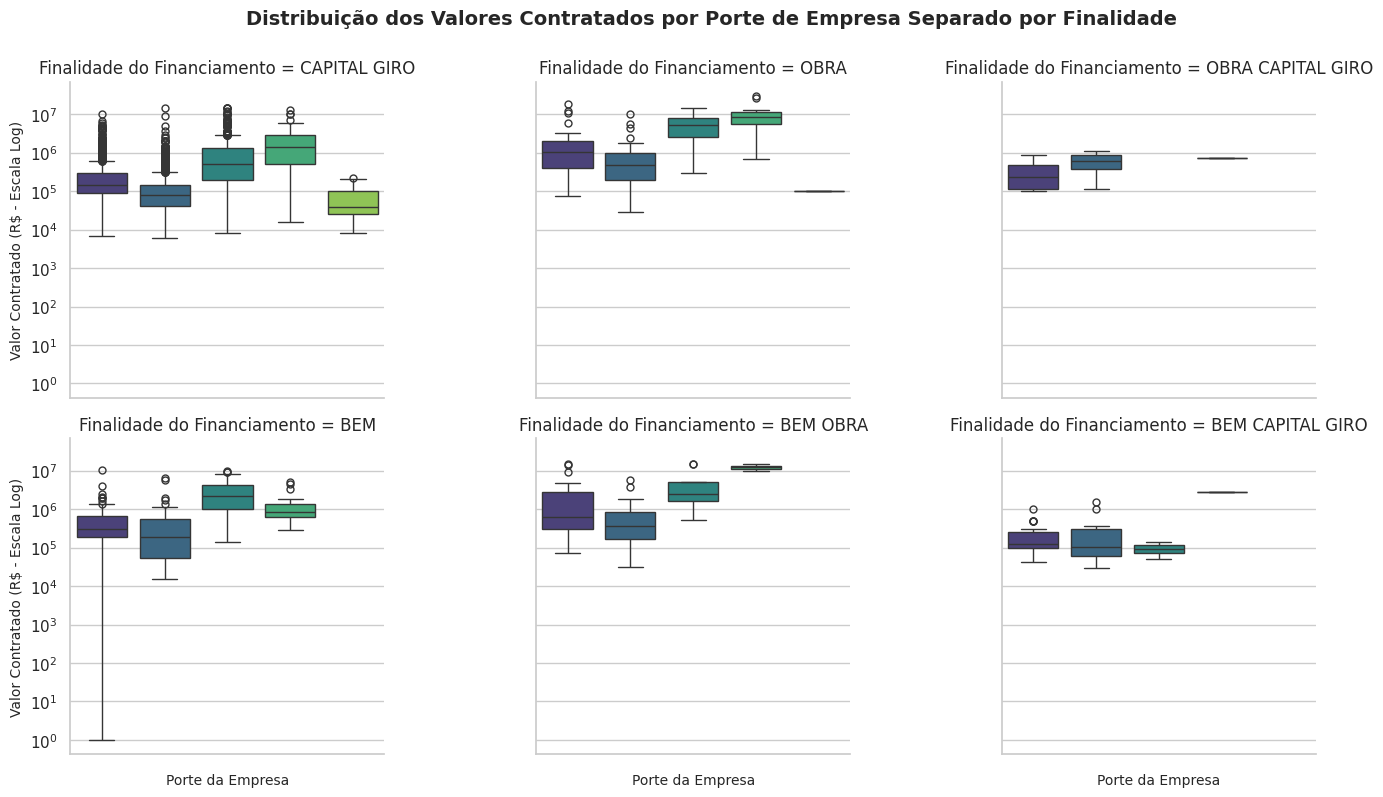

In [28]:
sns.set_theme(style="whitegrid")

# Criando um FacetGrid com catplot para separar os boxplots por Finalidade do Financiamento
g = sns.catplot(
    data=df_normalizado,
    x='Porte da Empresa',
    y='Valor Contratado',
    col='Finalidade do Financiamento',
    col_wrap=3,  # Organiza em até 3 colunas por linha
    kind='box',
    hue='Porte da Empresa',
    palette='viridis',
    legend=False,
    height=4,
    aspect=1.2
)

# Ajustar escala logarítmica e rótulos dos eixos
for ax in g.axes.flat:
    ax.set_yscale('log')  # Escala logarítmica para lidar com amplitudes extremas
    ax.set_ylabel('Valor Contratado (R$ - Escala Log)', fontsize=10)
    ax.set_xlabel('Porte da Empresa', fontsize=10)

# Ajustar rotação dos ticks horizontais de forma nativa e segura no FacetGrid
g.set_xticklabels(rotation=45, horizontalalignment='right', fontsize=9)

g.fig.suptitle('Distribuição dos Valores Contratados por Porte de Empresa Separado por Finalidade', y=1.02, fontsize=14, fontweight='bold')

plt.show()

### Agrupamento por Faixas de Valores Contratados (Tratamento de Outliers)

Para simplificar a visualização e mitigar o efeito dos outliers extremos identificados nos boxplots, criaremos faixas categóricas de valores para analisar a distribuição dos financiamentos de forma mais intuitiva.

In [29]:
# Definição dos limites e rótulos das faixas de valores contratados
limites_faixas = [0, 100000, 500000, 2000000, float('inf')]
rotulos_faixas = ['Até R$ 100k', 'R$ 100k a R$ 500k', 'R$ 500k a R$ 2M', 'Acima de R$ 2M']

# Criando a nova coluna de faixas de valor no DataFrame normalizado
df_normalizado['Faixa de Valor'] = pd.cut(
    df_normalizado['Valor Contratado'],
    bins=limites_faixas,
    labels=rotulos_faixas,
    right=True
)

# Visualizando a distribuição de frequência simples por faixa de valor
distribuicao_faixas = df_normalizado['Faixa de Valor'].value_counts().reset_index()
distribuicao_faixas.columns = ['Faixa de Valor', 'Quantidade de Contratos']
display(distribuicao_faixas)

,Faixa de Valor,Quantidade de Contratos
0,Até R$ 100k,2312
1,R$ 100k a R$ 500k,2267
2,R$ 500k a R$ 2M,577
3,Acima de R$ 2M,217


Agora, vamos construir uma visualização gráfica mostrando o percentual de contratos em cada faixa de valor, segmentados por **Porte da Empresa**.

<Figure size 1200x600 with 0 Axes>

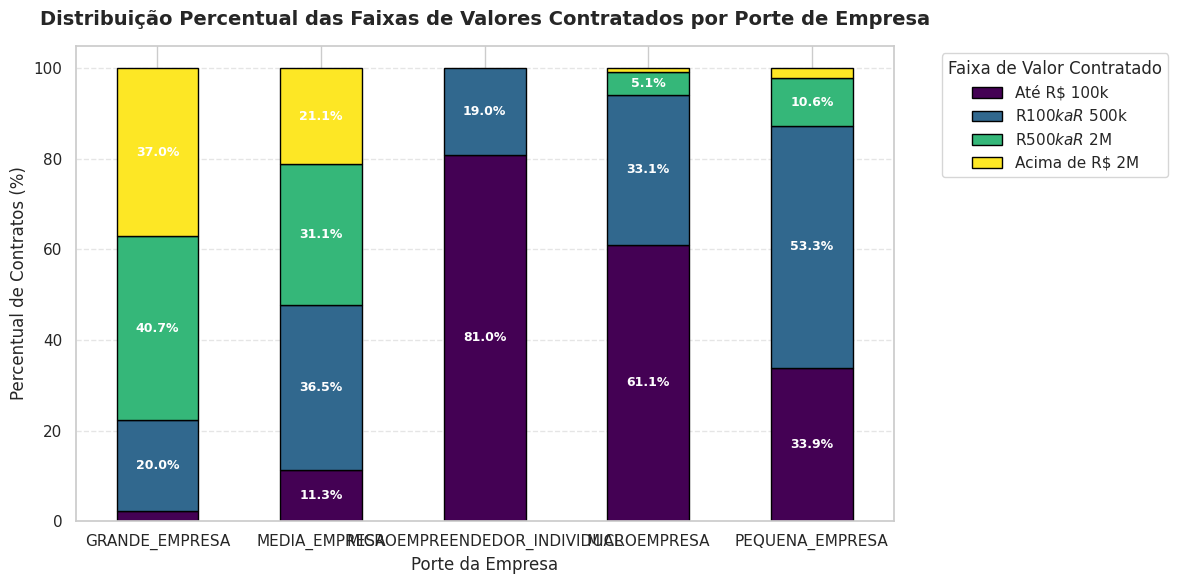

In [30]:
plt.figure(figsize=(12, 6))

# Calculando as proporções dentro de cada Porte da Empresa
df_agrupado = df_normalizado.groupby(['Porte da Empresa', 'Faixa de Valor'], observed=False).size().unstack(fill_value=0)
df_percentual = df_agrupado.div(df_agrupado.sum(axis=1), axis=0) * 100

# Plotando gráfico de barras empilhadas de forma limpa
ax = df_percentual.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis', edgecolor='black')

plt.title('Distribuição Percentual das Faixas de Valores Contratados por Porte de Empresa', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Porte da Empresa', fontsize=12)
plt.ylabel('Percentual de Contratos (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Faixa de Valor Contratado', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Adicionando rótulos percentuais dentro das barras
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 4:  # Só exibe se a barra for visível o suficiente
        ax.annotate(f'{height:.1f}%',
                    (x + width/2, y + height/2),
                    ha='center', va='center',
                    color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

### Cruzamento Triplo: Porte da Empresa, Faixa de Valor e Finalidade do Financiamento

Agora que mitigamos o efeito dos outliers criando faixas categóricas, vamos segmentar essa distribuição percentual também pelas diferentes finalidades do financiamento contratado para termos uma análise tridimensional completa.

In [31]:
# Tabela de dupla entrada mostrando a distribuição percentual das faixas por Porte e Finalidade
tabela_cruzada = pd.crosstab(
    index=[df_normalizado['Finalidade do Financiamento'], df_normalizado['Porte da Empresa']],
    columns=df_normalizado['Faixa de Valor'],
    normalize='index'
) * 100

print("=== DISTRIBUIÇÃO PERCENTUAL (%) DAS FAIXAS DE VALOR POR FINALIDADE E PORTE ===")
display(tabela_cruzada.round(1))

=== DISTRIBUIÇÃO PERCENTUAL (%) DAS FAIXAS DE VALOR POR FINALIDADE E PORTE ===


Faixa de Valor                                            Até R$ 100k  \
Finalidade do Financiamento Porte da Empresa                            
BEM                         GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                         0.0   
                            MICROEMPRESA                         38.0   
                            PEQUENA_EMPRESA                      13.0   
BEM CAPITAL GIRO            GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                        66.7   
                            MICROEMPRESA                         45.5   
                            PEQUENA_EMPRESA                      39.1   
BEM OBRA                    GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                         0.0   
                            MICROEMPRESA                          9.1   
                            PEQUENA_EMPRESA                       7.1   
CAPITAL GIRO                GRANDE_EMPRESA                        3.1   
                            MEDIA_EMPRESA                        12.2   
                            MICROEMPREENDEDOR_INDIVIDUAL         80.8   
                            MICROEMPRESA                         62.9   
                            PEQUENA_EMPRESA                      35.0   
OBRA                        GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                         0.0   
                            MICROEMPREENDEDOR_INDIVIDUAL        100.0   
                            MICROEMPRESA                         18.2   
                            PEQUENA_EMPRESA                       6.7   
OBRA CAPITAL GIRO           GRANDE_EMPRESA                        0.0   
                            MICROEMPRESA                          0.0   
                            PEQUENA_EMPRESA                      33.3   

Faixa de Valor                                            R$ 100k a R$ 500k  \
Finalidade do Financiamento Porte da Empresa                                  
BEM                         GRANDE_EMPRESA                             22.7   
                            MEDIA_EMPRESA                              12.5   
                            MICROEMPRESA                               36.0   
                            PEQUENA_EMPRESA                            48.1   
BEM CAPITAL GIRO            GRANDE_EMPRESA                              0.0   
                            MEDIA_EMPRESA                              33.3   
                            MICROEMPRESA                               36.4   
                            PEQUENA_EMPRESA                            56.5   
BEM OBRA                    GRANDE_EMPRESA                              0.0   
                            MEDIA_EMPRESA                               0.0   
                            MICROEMPRESA                               50.0   
                            PEQUENA_EMPRESA                            35.7   
CAPITAL GIRO                GRANDE_EMPRESA                             22.4   
                            MEDIA_EMPRESA                              39.7   
                            MICROEMPREENDEDOR_INDIVIDUAL               19.2   
                            MICROEMPRESA                               32.8   
                            PEQUENA_EMPRESA                            54.0   
OBRA                        GRANDE_EMPRESA                              0.0   
                            MEDIA_EMPRESA                               7.1   
                            MICROEMPREENDEDOR_INDIVIDUAL                0.0   
                            MICROEMPRESA                               31.8   
                            PEQUENA_EMPRESA                            26.7   
OBRA CAPITAL GIRO           GRANDE_EMPRESA                              0.0   
                            MICROEMPRESA             

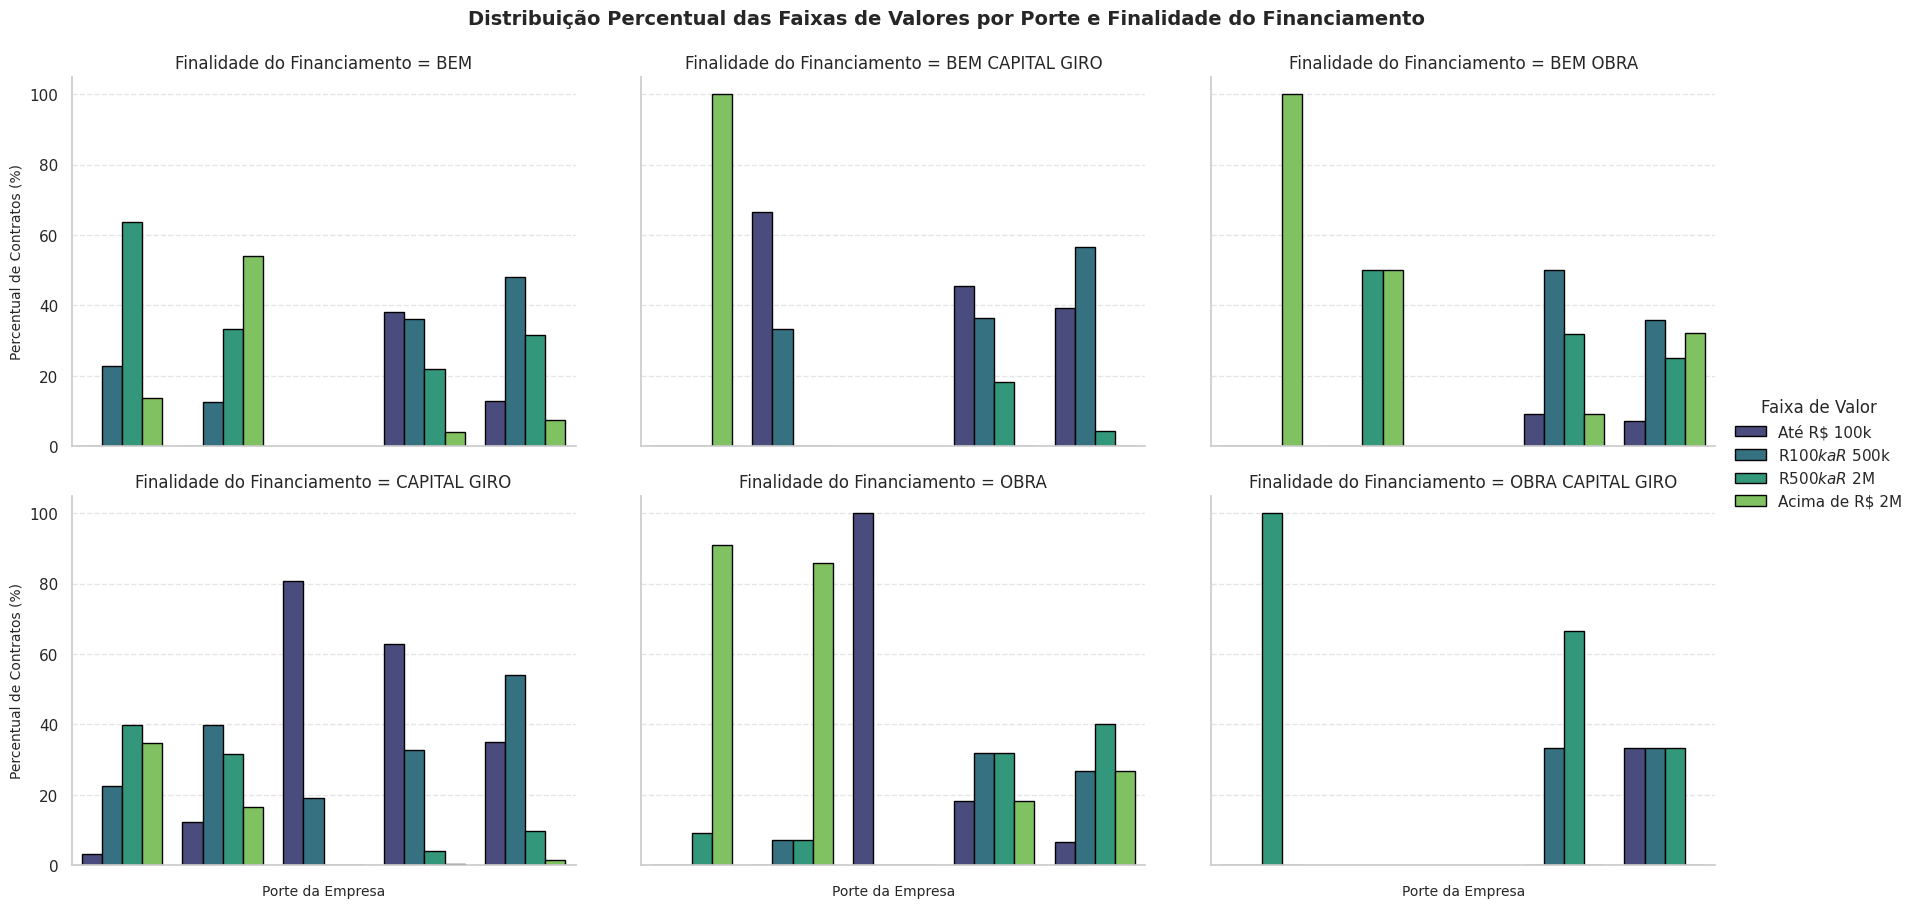

In [32]:
# Gráfico de barras facetado por Finalidade de Financiamento utilizando Seaborn catplot
df_melted = df_normalizado.groupby(['Finalidade do Financiamento', 'Porte da Empresa', 'Faixa de Valor'], observed=False).size().reset_index(name='Contratos')

# Calcular percentual dentro de cada grupo de Finalidade e Porte
grupo_total = df_melted.groupby(['Finalidade do Financiamento', 'Porte da Empresa'], observed=False)['Contratos'].transform('sum')
df_melted['Percentual'] = (df_melted['Contratos'] / grupo_total) * 100

# Plot facetado utilizando catplot do seaborn
g_faixas = sns.catplot(
    data=df_melted,
    x='Porte da Empresa',
    y='Percentual',
    hue='Faixa de Valor',
    col='Finalidade do Financiamento',
    col_wrap=3,
    kind='bar',
    palette='viridis',
    height=4.5,
    aspect=1.3,
    edgecolor='black'
)

# Detalhes de formatação dos eixos
for ax in g_faixas.axes.flat:
    ax.set_ylabel('Percentual de Contratos (%)', fontsize=10)
    ax.set_xlabel('Porte da Empresa', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

g_faixas.set_xticklabels(rotation=45, horizontalalignment='right', fontsize=9)
g_faixas.fig.suptitle('Distribuição Percentual das Faixas de Valores por Porte e Finalidade do Financiamento', y=1.03, fontsize=14, fontweight='bold')

plt.show()

### Cruzamento Triplo: Porte da Empresa, Faixa de Valor e Finalidade do Financiamento

Agora que mitigamos o efeito dos outliers criando faixas categóricas, vamos segmentar essa distribuição percentual também pelas diferentes finalidades do financiamento contratado.

In [33]:
# Tabela de dupla entrada mostrando a distribuição percentual das faixas por Porte e Finalidade
tabela_cruzada = pd.crosstab(
    index=[df_normalizado['Finalidade do Financiamento'], df_normalizado['Porte da Empresa']],
    columns=df_normalizado['Faixa de Valor'],
    normalize='index'  # Normaliza para obter o percentual por linha (Finalidade + Porte)
) * 100

print("=== DISTRIBUIÇÃO PERCENTUAL (%) DAS FAIXAS DE VALOR POR FINALIDADE E PORTE ===")
display(tabela_cruzada.round(1))

=== DISTRIBUIÇÃO PERCENTUAL (%) DAS FAIXAS DE VALOR POR FINALIDADE E PORTE ===


Faixa de Valor                                            Até R$ 100k  \
Finalidade do Financiamento Porte da Empresa                            
BEM                         GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                         0.0   
                            MICROEMPRESA                         38.0   
                            PEQUENA_EMPRESA                      13.0   
BEM CAPITAL GIRO            GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                        66.7   
                            MICROEMPRESA                         45.5   
                            PEQUENA_EMPRESA                      39.1   
BEM OBRA                    GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                         0.0   
                            MICROEMPRESA                          9.1   
                            PEQUENA_EMPRESA                       7.1   
CAPITAL GIRO                GRANDE_EMPRESA                        3.1   
                            MEDIA_EMPRESA                        12.2   
                            MICROEMPREENDEDOR_INDIVIDUAL         80.8   
                            MICROEMPRESA                         62.9   
                            PEQUENA_EMPRESA                      35.0   
OBRA                        GRANDE_EMPRESA                        0.0   
                            MEDIA_EMPRESA                         0.0   
                            MICROEMPREENDEDOR_INDIVIDUAL        100.0   
                            MICROEMPRESA                         18.2   
                            PEQUENA_EMPRESA                       6.7   
OBRA CAPITAL GIRO           GRANDE_EMPRESA                        0.0   
                            MICROEMPRESA                          0.0   
                            PEQUENA_EMPRESA                      33.3   

Faixa de Valor                                            R$ 100k a R$ 500k  \
Finalidade do Financiamento Porte da Empresa                                  
BEM                         GRANDE_EMPRESA                             22.7   
                            MEDIA_EMPRESA                              12.5   
                            MICROEMPRESA                               36.0   
                            PEQUENA_EMPRESA                            48.1   
BEM CAPITAL GIRO            GRANDE_EMPRESA                              0.0   
                            MEDIA_EMPRESA                              33.3   
                            MICROEMPRESA                               36.4   
                            PEQUENA_EMPRESA                            56.5   
BEM OBRA                    GRANDE_EMPRESA                              0.0   
                            MEDIA_EMPRESA                               0.0   
                            MICROEMPRESA                               50.0   
                            PEQUENA_EMPRESA                            35.7   
CAPITAL GIRO                GRANDE_EMPRESA                             22.4   
                            MEDIA_EMPRESA                              39.7   
                            MICROEMPREENDEDOR_INDIVIDUAL               19.2   
                            MICROEMPRESA                               32.8   
                            PEQUENA_EMPRESA                            54.0   
OBRA                        GRANDE_EMPRESA                              0.0   
                            MEDIA_EMPRESA                               7.1   
                            MICROEMPREENDEDOR_INDIVIDUAL                0.0   
                            MICROEMPRESA                               31.8   
                            PEQUENA_EMPRESA                            26.7   
OBRA CAPITAL GIRO           GRANDE_EMPRESA                              0.0   
                            MICROEMPRESA             

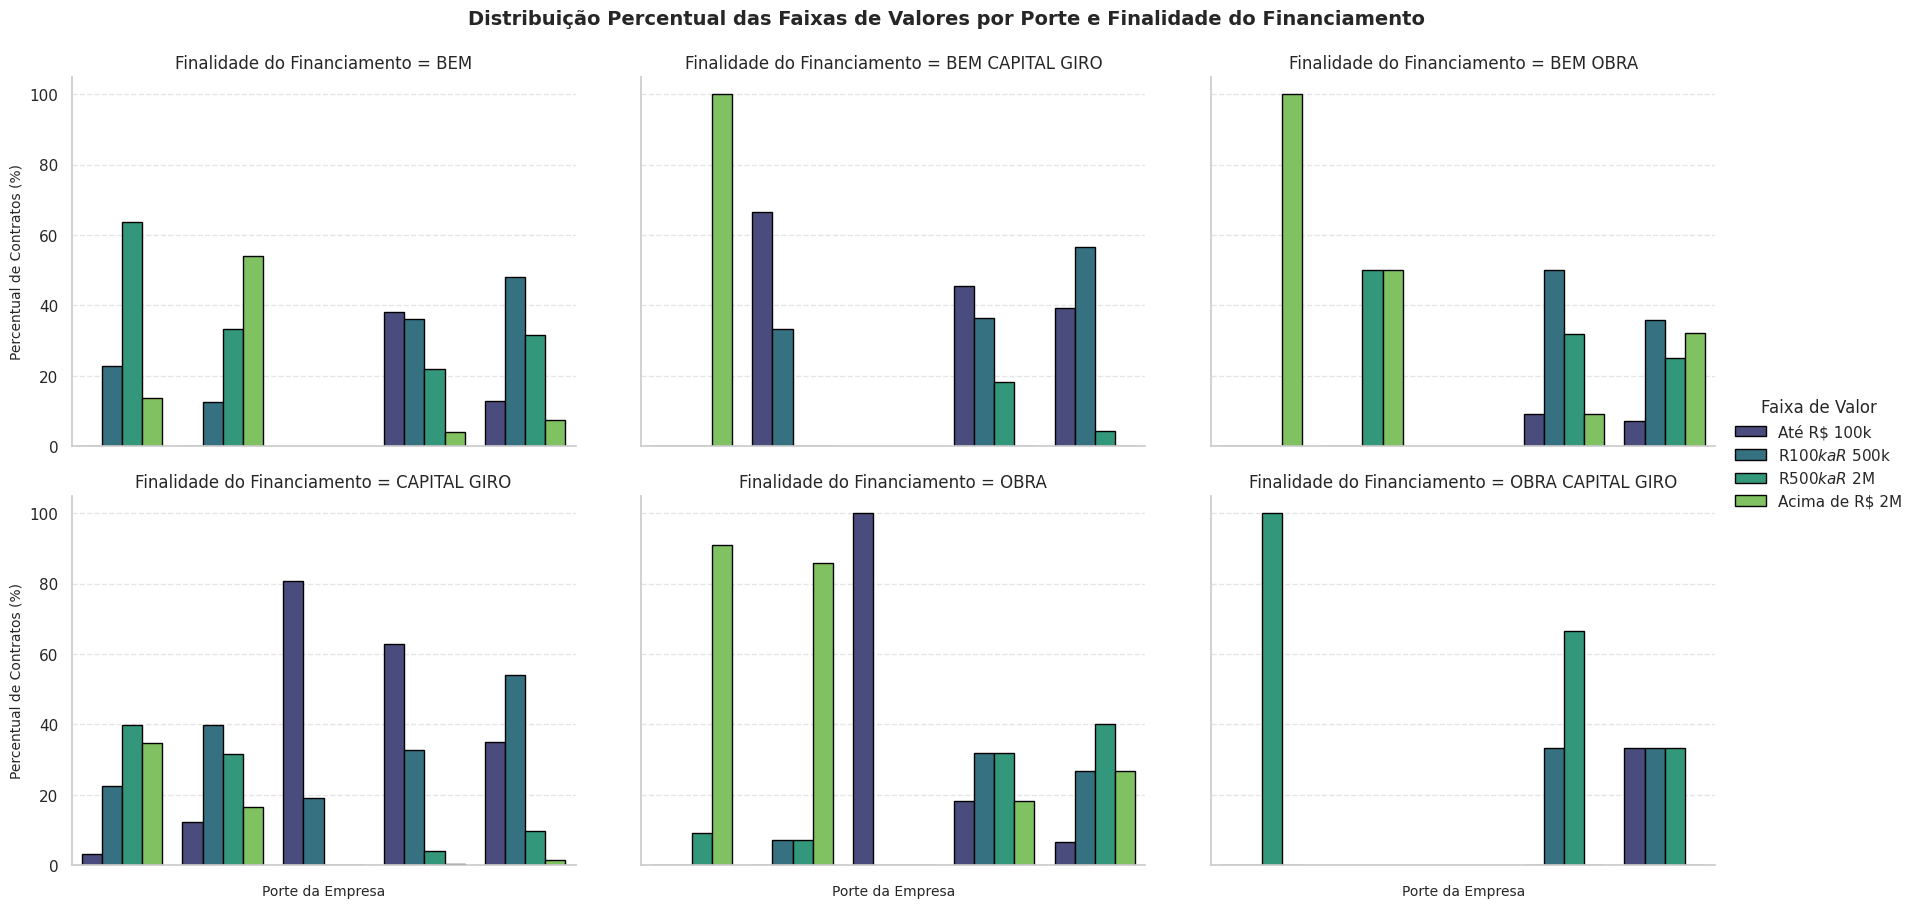

In [34]:
# Gráfico de barras facetado por Finalidade de Financiamento utilizando Seaborn catplot
# Para isso, reorganizamos os dados para o formato longo (melted)
df_melted = df_normalizado.groupby(['Finalidade do Financiamento', 'Porte da Empresa', 'Faixa de Valor'], observed=False).size().reset_index(name='Contratos')

# Calcular percentual dentro de cada grupo de Finalidade e Porte
grupo_total = df_melted.groupby(['Finalidade do Financiamento', 'Porte da Empresa'], observed=False)['Contratos'].transform('sum')
df_melted['Percentual'] = (df_melted['Contratos'] / grupo_total) * 100

# Plot facetado utilizando catplot do seaborn
g_faixas = sns.catplot(
    data=df_melted,
    x='Porte da Empresa',
    y='Percentual',
    hue='Faixa de Valor',
    col='Finalidade do Financiamento',
    col_wrap=3,
    kind='bar',
    palette='viridis',
    height=4.5,
    aspect=1.3,
    edgecolor='black'
)

# Detalhes de formatação dos eixos
for ax in g_faixas.axes.flat:
    ax.set_ylabel('Percentual de Contratos (%)', fontsize=10)
    ax.set_xlabel('Porte da Empresa', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

g_faixas.set_xticklabels(rotation=45, horizontalalignment='right', fontsize=9)
g_faixas.fig.suptitle('Distribuição Percentual das Faixas de Valores por Porte e Finalidade do Financiamento', y=1.03, fontsize=14, fontweight='bold')

plt.show()

## Análise por Agente Financeiro

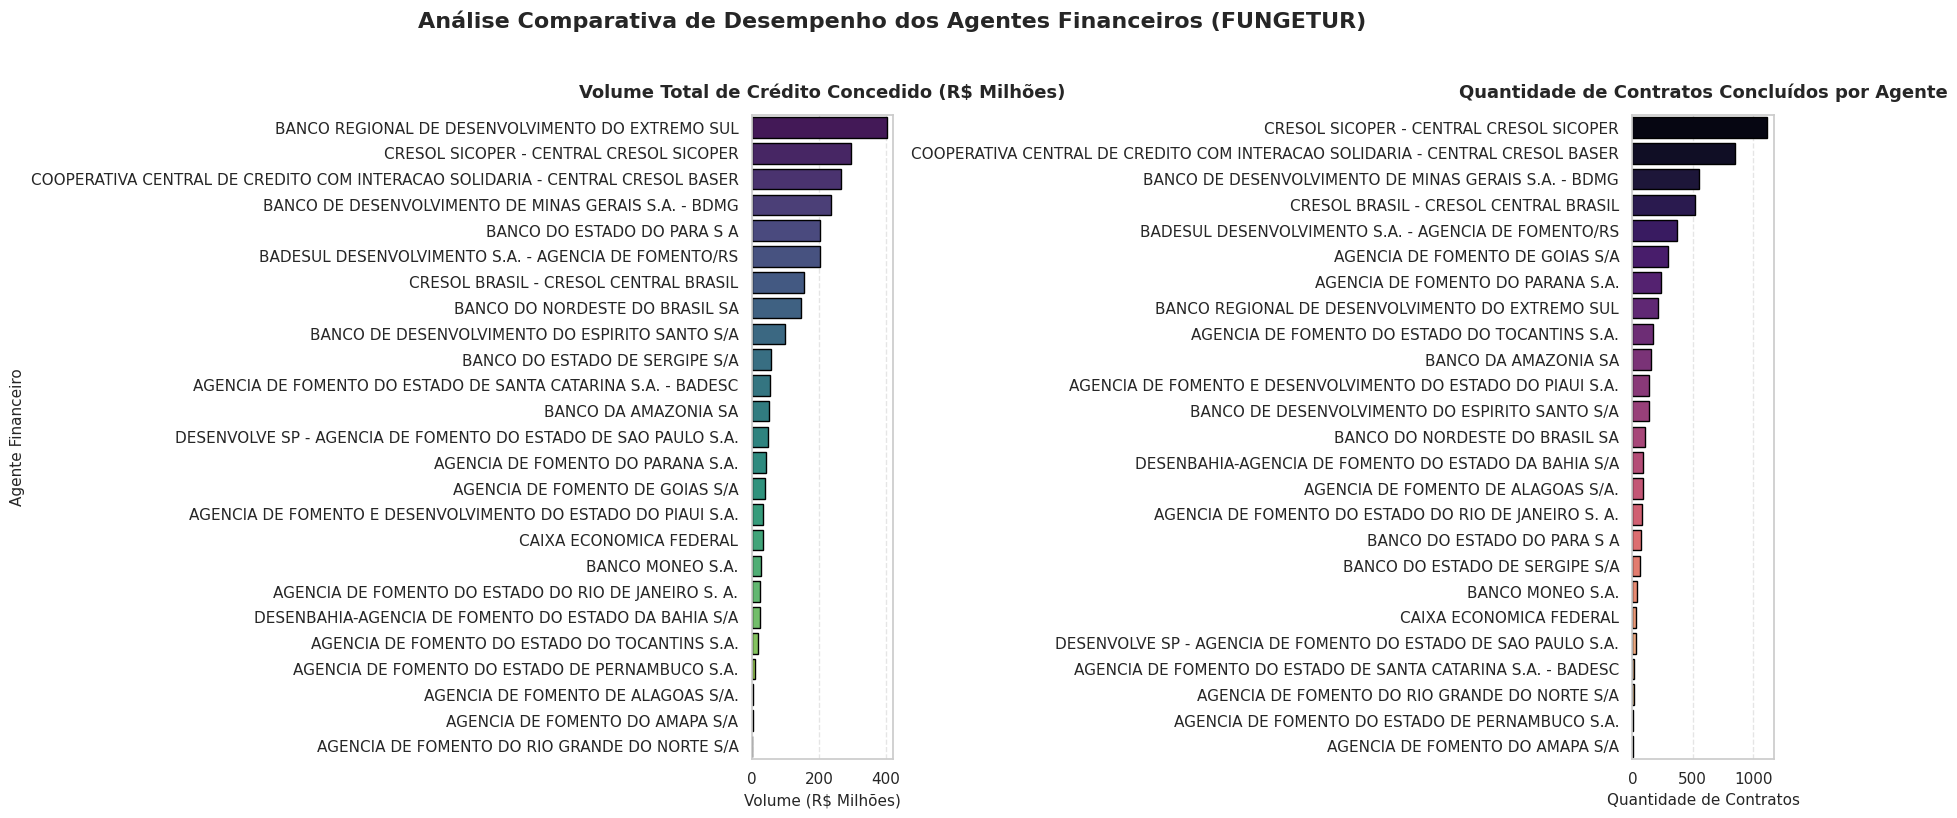

In [35]:
# Agrupando e preparando os dados por Agente Financeiro
df_agentes = df_normalizado.groupby('Agente Financeiro').agg(
    volume_total=('Valor Contratado', 'sum'),
    total_contratos=('Valor Contratado', 'count')
).reset_index().sort_values(by='volume_total', ascending=False)

# Adicionando representação em milhões para facilitar a leitura dos eixos
df_agentes['volume_milhoes'] = df_agentes['volume_total'] / 1e6

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Grafico 1: Volume Total de Crédito em Milhões por Agente Financeiro
sns.barplot(
    data=df_agentes.sort_values(by='volume_milhoes', ascending=False),
    x='volume_milhoes',
    y='Agente Financeiro',
    hue='Agente Financeiro',
    ax=axes[0],
    palette='viridis',
    legend=False,
    edgecolor='black'
)
axes[0].set_title('Volume Total de Crédito Concedido (R$ Milhões)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Volume (R$ Milhões)', fontsize=11)
axes[0].set_ylabel('Agente Financeiro', fontsize=11)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Grafico 2: Total de Contratos Gerados por Agente Financeiro
sns.barplot(
    data=df_agentes.sort_values(by='total_contratos', ascending=False),
    x='total_contratos',
    y='Agente Financeiro',
    hue='Agente Financeiro',
    ax=axes[1],
    palette='magma',
    legend=False,
    edgecolor='black'
)
axes[1].set_title('Quantidade de Contratos Concluídos por Agente', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Quantidade de Contratos', fontsize=11)
axes[1].set_ylabel('', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle('Análise Comparativa de Desempenho dos Agentes Financeiros (FUNGETUR)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Análise de Concentração de Contratos: Agente Financeiro por Município

Nesta seção, identificamos quais municípios registram a maior quantidade de contratos para cada Agente Financeiro, permitindo compreender a capilaridade geográfica e os principais polos de atuação de cada parceiro.

In [36]:
# Agrupando os dados para calcular a quantidade de contratos por Agente e Município
df_concentracao = df_normalizado.groupby(['Agente Financeiro', 'Município', 'UF']).size().reset_index(name='Quantidade de Contratos')

# Identificando o município com maior número de contratos para cada Agente Financeiro
idx_max = df_concentracao.groupby('Agente Financeiro')['Quantidade de Contratos'].idxmax()
df_lideres_municipio = df_concentracao.loc[idx_max].sort_values(by='Quantidade de Contratos', ascending=False)

# Exibindo o ranking dos agentes e seus principais polos de atuação municipais
print("=== MUNICÍPIO COM MAIOR CONCENTRAÇÃO DE CONTRATOS POR AGENTE FINANCEIRO ===")
display(df_lideres_municipio.reset_index(drop=True))

=== MUNICÍPIO COM MAIOR CONCENTRAÇÃO DE CONTRATOS POR AGENTE FINANCEIRO ===


,Agente Financeiro,Município,UF,Quantidade de Contratos
0,AGENCIA DE FOMENTO DE GOIAS S/A,GOIÂNIA,GO,138
1,AGENCIA DE FOMENTO DO PARANA S.A.,CURITIBA,PR,103
2,AGENCIA DE FOMENTO DO ESTADO DO TOCANTINS S.A.,PALMAS,TO,99
3,BANCO DE DESENVOLVIMENTO DE MINAS GERAIS S.A. ...,BELO HORIZONTE,MG,82
4,AGENCIA DE FOMENTO E DESENVOLVIMENTO DO ESTADO...,TERESINA,PI,82
5,BADESUL DESENVOLVIMENTO S.A. - AGENCIA DE FOME...,PORTO ALEGRE,RS,70
6,BANCO DO ESTADO DO PARA S A,BELÉM,PA,47
7,AGENCIA DE FOMENTO DE ALAGOAS S/A.,MACEIÓ,AL,47
8,BANCO DE DESENVOLVIMENTO DO ESPIRITO SANTO S/A,VITÓRIA,ES,41
9,CRESOL SICOPER - CENTRAL CRESOL SICOPER,FREDERICO WESTPHALEN,RS,39


## Análise da Distribuição Territorial por Unidade Federativa (UF)

Nesta seção, analisamos como os recursos e a quantidade de contratos do FUNGETUR estão distribuídos geograficamente entre as diferentes Unidades Federativas (UF) do Brasil.

### Análise da Distribuição por Região Geográfica

Nesta etapa, criamos o mapeamento das UFs para suas respectivas regiões geográficas brasileiras para compreender a distribuição do crédito FUNGETUR de forma consolidada regionalmente.

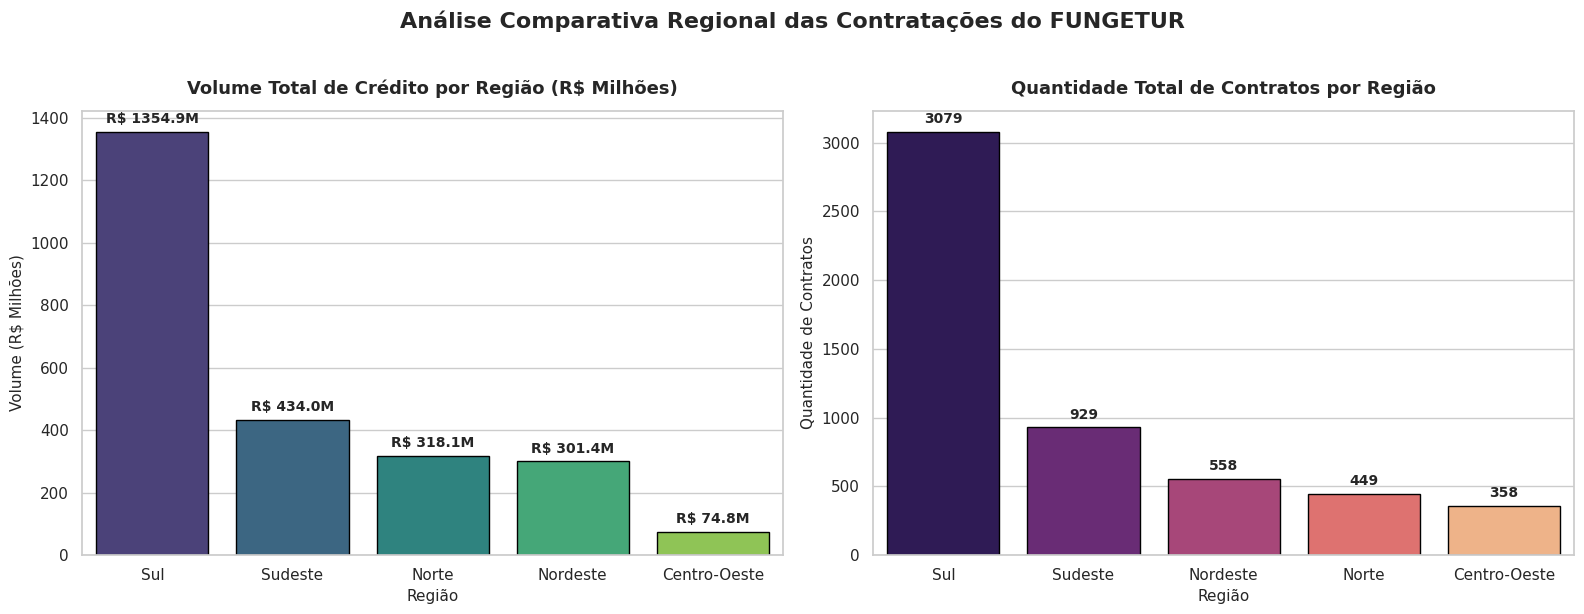

In [37]:
# Dicionário de mapeamento de UF para Região
mapeamento_regioes = {
    'AC': 'Norte', 'AM': 'Norte', 'AP': 'Norte', 'PA': 'Norte', 'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
    'AL': 'Nordeste', 'BA': 'Nordeste', 'CE': 'Nordeste', 'MA': 'Nordeste', 'PB': 'Nordeste', 'PE': 'Nordeste', 'PI': 'Nordeste', 'RN': 'Nordeste', 'SE': 'Nordeste',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste',
    'ES': 'Sudeste', 'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul'
}

# Criando a coluna de Região no DataFrame
df_normalizado['Regiao'] = df_normalizado['UF'].map(mapeamento_regioes)

# Agrupando por Região
df_regiao = df_normalizado.groupby('Regiao').agg(
    volume_total=('Valor Contratado', 'sum'),
    total_contratos=('Valor Contratado', 'count')
).reset_index()

# Convertendo volume para milhões de reais
df_regiao['volume_milhoes'] = df_regiao['volume_total'] / 1e6

# Ordenando para exibição
df_regiao_volume = df_regiao.sort_values(by='volume_milhoes', ascending=False)
df_regiao_contratos = df_regiao.sort_values(by='total_contratos', ascending=False)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Volume por Região
sns.barplot(
    data=df_regiao_volume,
    x='Regiao',
    y='volume_milhoes',
    hue='Regiao',
    ax=axes[0],
    palette='viridis',
    legend=False,
    edgecolor='black'
)
axes[0].set_title('Volume Total de Crédito por Região (R$ Milhões)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Volume (R$ Milhões)', fontsize=11)
axes[0].set_xlabel('Região', fontsize=11)

# Adicionando rótulos nos valores das barras
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'R$ {height:.1f}M',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                textcoords='offset points')

# Gráfico 2: Quantidade de Contratos por Região
sns.barplot(
    data=df_regiao_contratos,
    x='Regiao',
    y='total_contratos',
    hue='Regiao',
    ax=axes[1],
    palette='magma',
    legend=False,
    edgecolor='black'
)
axes[1].set_title('Quantidade Total de Contratos por Região', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Quantidade de Contratos', fontsize=11)
axes[1].set_xlabel('Região', fontsize=11)

for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{int(height)}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                textcoords='offset points')

plt.suptitle('Análise Comparativa Regional das Contratações do FUNGETUR', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

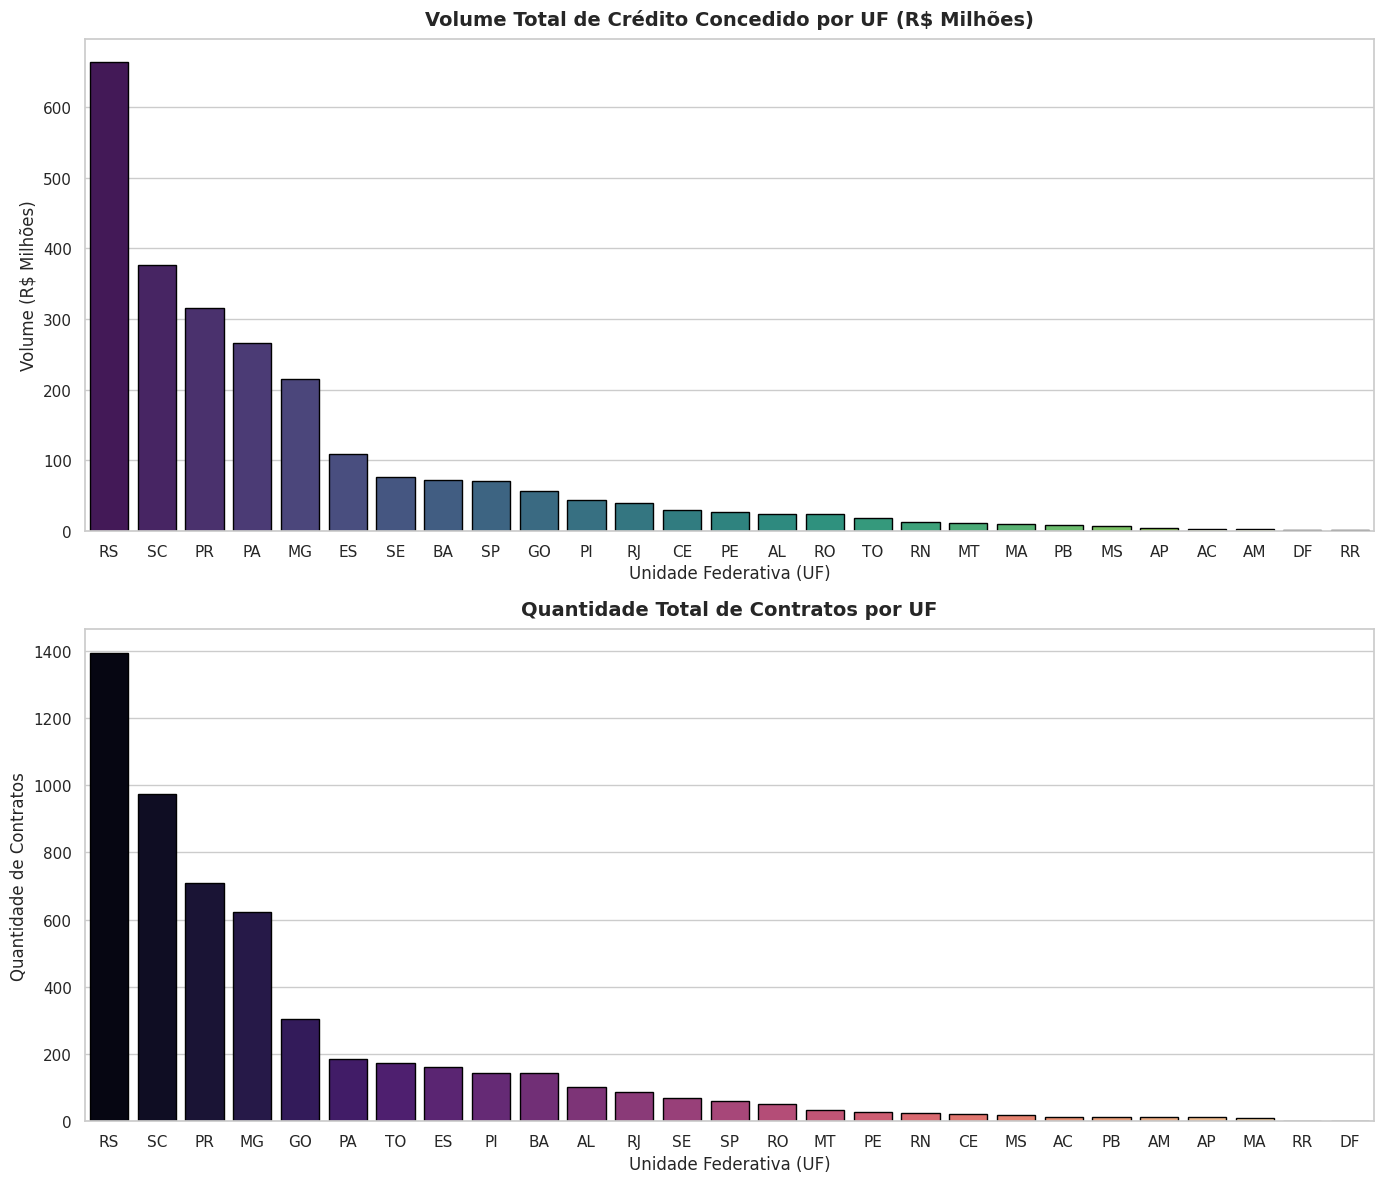

In [38]:
# Agrupando os dados por UF
df_uf = df_normalizado.groupby('UF').agg(
    volume_total=('Valor Contratado', 'sum'),
    total_contratos=('Valor Contratado', 'count')
).reset_index()

# Criando métrica em milhões para melhor visualização
df_uf['volume_milhoes'] = df_uf['volume_total'] / 1e6

# Ordenando os dados para os gráficos
df_uf_volume = df_uf.sort_values(by='volume_milhoes', ascending=False)
df_uf_contratos = df_uf.sort_values(by='total_contratos', ascending=False)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Gráfico 1: Volume Financeiro por UF
sns.barplot(
    data=df_uf_volume,
    x='UF',
    y='volume_milhoes',
    hue='UF',
    ax=axes[0],
    palette='viridis',
    legend=False,
    edgecolor='black'
)
axes[0].set_title('Volume Total de Crédito Concedido por UF (R$ Milhões)', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Volume (R$ Milhões)', fontsize=12)
axes[0].set_xlabel('Unidade Federativa (UF)', fontsize=12)

# Gráfico 2: Quantidade de Contratos por UF
sns.barplot(
    data=df_uf_contratos,
    x='UF',
    y='total_contratos',
    hue='UF',
    ax=axes[1],
    palette='magma',
    legend=False,
    edgecolor='black'
)
axes[1].set_title('Quantidade Total de Contratos por UF', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('Quantidade de Contratos', fontsize=12)
axes[1].set_xlabel('Unidade Federativa (UF)', fontsize=12)

plt.tight_layout()
plt.show()

### Análise de Contratantes: Clientes Distintos e Concentração de Crédito

In [39]:
# 1) Estatísticas Gerais de Clientes
total_operacoes = len(df_normalizado)
clientes_unicos = df_normalizado['CPF/CNPJ do Contratante'].nunique()

# Agrupando por cliente para obter o volume total contratado por cada um
df_clientes = df_normalizado.groupby('CPF/CNPJ do Contratante').agg(
    volume_total=('Valor Contratado', 'sum'),
    qtd_contratos=('Valor Contratado', 'count')
).reset_index().sort_values(by='volume_total', ascending=False)

# Métricas de concentração
volume_total_geral = df_clientes['volume_total'].sum()
df_clientes['percentual_do_total'] = (df_clientes['volume_total'] / volume_total_geral) * 100
df_clientes['percentual_acumulado'] = df_clientes['percentual_do_total'].cumsum()

print(f"=== ESTATÍSTICAS GERAIS DOS CONTRATANTES ===")
print(f"Total de Operações na Base: {total_operacoes}")
print(f"Total de Clientes Distintos (CPF/CNPJ): {clientes_unicos}")
print(f"Média de Contratos por Cliente: {total_operacoes / clientes_unicos:.2f}")
print(f"Ticket Médio por Cliente: R$ {volume_total_geral / clientes_unicos:,.2f}")
print(f"Maior Volume Concedido a um único Cliente: R$ {df_clientes['volume_total'].max():,.2f}")
print(f"Menor Volume Concedido a um único Cliente: R$ {df_clientes['volume_total'].min():,.2f}")
print("\n")

# 2) Análise de Concentração (Top Clientes)
top_10_volume = df_clientes.head(10)['percentual_do_total'].sum()
top_50_volume = df_clientes.head(50)['percentual_do_total'].sum()
top_100_volume = df_clientes.head(100)['percentual_do_total'].sum()

print(f"=== ANÁLISE DE CONCENTRAÇÃO DE RECURSOS ===")
print(f"Top 10 Clientes concentram: {top_10_volume:.2f}% do volume total de crédito.")
print(f"Top 50 Clientes concentram: {top_50_volume:.2f}% do volume total de crédito.")
print(f"Top 100 Clientes concentram: {top_100_volume:.2f}% do volume total de crédito.")


=== ESTATÍSTICAS GERAIS DOS CONTRATANTES ===
Total de Operações na Base: 5373
Total de Clientes Distintos (CPF/CNPJ): 4926
Média de Contratos por Cliente: 1.09
Ticket Médio por Cliente: R$ 504,100.09
Maior Volume Concedido a um único Cliente: R$ 30,000,000.00
Menor Volume Concedido a um único Cliente: R$ 1.00


=== ANÁLISE DE CONCENTRAÇÃO DE RECURSOS ===
Top 10 Clientes concentram: 10.15% do volume total de crédito.
Top 50 Clientes concentram: 29.59% do volume total de crédito.
Top 100 Clientes concentram: 40.83% do volume total de crédito.


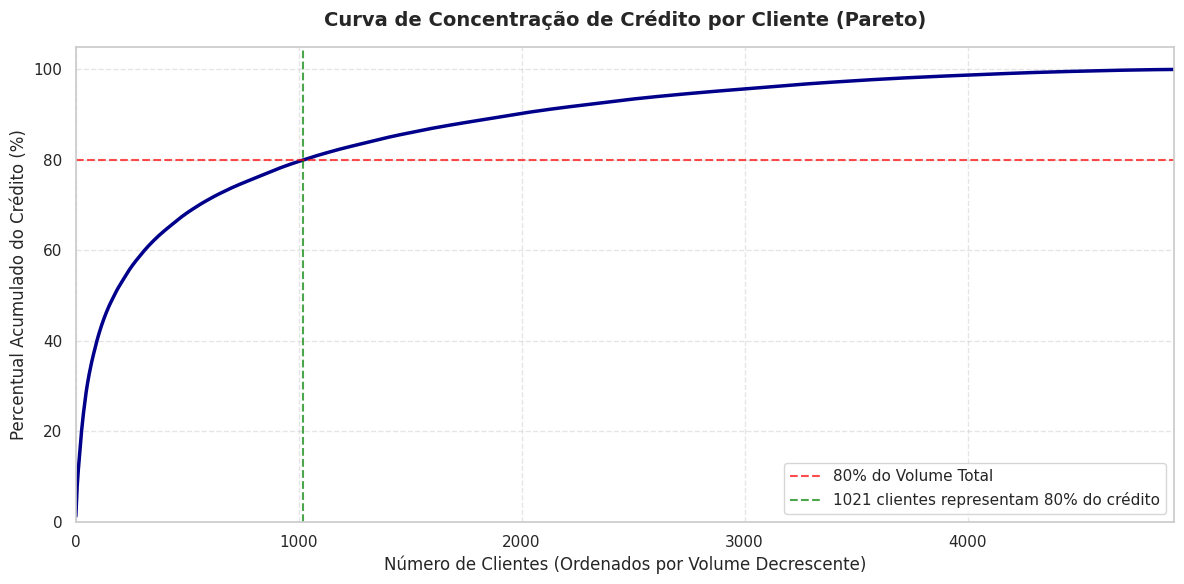

In [40]:
# 3) Plotando a Curva de Concentração Acumulada (Curva de Pareto)
plt.figure(figsize=(12, 6))
plt.plot(np.arange(1, len(df_clientes) + 1), df_clientes['percentual_acumulado'].values, color='darkblue', linewidth=2.5)
plt.axhline(y=80, color='red', linestyle='--', alpha=0.7, label='80% do Volume Total')

# Encontrar quantos clientes representam 80% do crédito
clientes_80_pct = (df_clientes['percentual_acumulado'] <= 80).sum()
plt.axvline(x=clientes_80_pct, color='green', linestyle='--', alpha=0.7, label=f'{clientes_80_pct} clientes representam 80% do crédito')

plt.title('Curva de Concentração de Crédito por Cliente (Pareto)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Clientes (Ordenados por Volume Decrescente)', fontsize=12)
plt.ylabel('Percentual Acumulado do Crédito (%)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(0, len(df_clientes))
plt.ylim(0, 105)

plt.tight_layout()
plt.show()

## 📋 RESUMO EXECUTIVO: Principais Descobertas do Projeto (FUNGETUR)

### 1. Saneamento e Qualidade de Dados
* **Inconsistências Temporais Identificadas:** A base bruta continha outliers impossíveis que extrapolavam as regras de concessão do produto (prazos de até 319 anos e carências de até 63 anos).
* **Metodologia de Resolução:** Foi aplicada a **Estratégia 7** (imputação com base na mediana dos valores válidos segmentada por finalidade de financiamento), reduzindo o desvio padrão de **114,6** para **24,2** nos prazos e garantindo integridade analítica para os dados subsequentes sem perda de registros.

### 2. Perfil de Distribuição por Porte e Democratização do Crédito
* **Forte Apoio às PMEs:** O programa cumpre seu papel de democratização do crédito. As **Microempresas (ME)** e **Pequenas Empresas (EPP)** dominam amplamente a quantidade de contratos em quase todas as finalidades de financiamento.
* **Capacidade de Atendimento:** O ticket médio por cliente é de **R$ 504.100,09**, mostrando pulverização saudável de recursos em contrapartida a grandes tomadores de crédito.
* **Análise de Concentração (Pareto):** O projeto confirmou uma baixa concentração: os 10 maiores clientes concentram apenas **10,15%** do volume financeiro total, e são necessários **1.021 clientes** para acumular 80% de todo o crédito concedido na base.

### 3. Dinâmica dos Agentes Financeiros
* **Volume Financeiro vs. Capilaridade:**
  * O **BRDE** (Banco Regional de Desenvolvimento do Extremo Sul) lidera o volume total de crédito concedido (passando de R$ 400 Milhões).
  * A **Cresol** (Cresol Sicoper e Cresol Baser) se destaca massivamente no quesito capilaridade de microcrédito, concentrando o maior número de contratos individuais concluídos.

### 4. Distribuição Territorial e Regionalidade
* **Concentração no Sul:** A **Região Sul** é disparada o polo de maior fomento da carteira FUNGETUR analisada, concentrando mais de **R$ 1,35 Bilhão** distribuídos em mais de **3.079 contratos**.
* **Liderança por UF:** O **Rio Grande do Sul (RS)** figura como o estado líder em volume financeiro e quantidade de contratos, seguido por Santa Catarina (SC) e Paraná (PR).